In [1]:
!python -m pip install streamlit pandas scikit-learn matplotlib wordcloud


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

# ============================================================
# 1. IMPORT LIBRARY
# ============================================================

import os
import re
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Library berhasil diimport.")


Library berhasil diimport.


In [3]:

# Nama file dataset
DATA_FILE = (r"C:\Users\Hype AMD\Documents\tugas caca\tweet_data_kesehatan .csv")

# Jika file berada di folder lain, sesuaikan path di atas.
# Dataset menggunakan pemisah titik koma (;)
df = pd.read_csv(DATA_FILE, sep=";")

print("Ukuran dataset:", df.shape)
print("Kolom:", df.columns.tolist())
display(df.head())


Ukuran dataset: (1206, 4)
Kolom: ['created_at', 'username', 'full_text', 'sentimen']


,created_at,username,full_text,sentimen
0,2026-08-01 02:06:28,nakes_borneo98,RT @kabar_news95: Sistem pendaftaran donor dar...,negatif
1,2026-08-01 03:53:59,bapak_pontianak816,Pemerintah Banjarmasin menggelar rapat koordin...,netral
2,2026-08-01 04:05:11,bapak_nusantara422,"Syukur ibu saya sudah pulih dari flu, terima k...",positif
3,2026-08-01 06:25:26,warga_hari_ini336,Pemerintah Bandung menggelar rapat koordinasi ...,netral
4,2026-08-01 09:43:00,dokter_hari_ini86,RT @sehat_indonesia982: Kemenkes merilis pedom...,netral


In [4]:
print("Informasi dataset:")
df.info()

print("\nJumlah missing value:")
display(df.isnull().sum())

print("\nDistribusi sentimen:")
display(df["sentimen"].value_counts(dropna=False))

print("\nContoh data:")
display(df[["full_text", "sentimen"]].head(10))


Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 1206 entries, 0 to 1205
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   created_at  1200 non-null   str  
 1   username    1200 non-null   str  
 2   full_text   1200 non-null   str  
 3   sentimen    1200 non-null   str  
dtypes: str(4)
memory usage: 191.1 KB

Jumlah missing value:


created_at    6
username      6
full_text     6
sentimen      6
dtype: int64


Distribusi sentimen:


sentimen
negatif    488
positif    421
netral     291
NaN          6
Name: count, dtype: int64


Contoh data:


,full_text,sentimen
0,RT @kabar_news95: Sistem pendaftaran donor dar...,negatif
1,Pemerintah Banjarmasin menggelar rapat koordin...,netral
2,"Syukur ibu saya sudah pulih dari flu, terima k...",positif
3,Pemerintah Bandung menggelar rapat koordinasi ...,netral
4,RT @sehat_indonesia982: Kemenkes merilis pedom...,netral
5,RT @nakes_indonesia258: Pemerintah Banjarmasin...,netral
6,"Lega banget, hasil lab aman dan bidan menjelas...",positif
7,"Kasus hipertensi meningkat di Palembang, warga...",negatif
8,RT @warga_borneo241: Syukur ibu saya sudah pul...,positif
9,RT @dokter_hari_ini876: Salut untuk apoteker d...,positif


In [5]:
# Pastikan kolom yang diperlukan tersedia
required_cols = ["full_text", "sentimen"]

for col in required_cols:
    if col not in df.columns:
        raise ValueError(f"Kolom '{col}' tidak ditemukan.")

# Hapus baris yang tidak memiliki teks atau label
df = df.dropna(subset=["full_text", "sentimen"]).copy()

# Ubah menjadi string
df["full_text"] = df["full_text"].astype(str)
df["sentimen"] = df["sentimen"].astype(str).str.strip().str.lower()

# Hanya gunakan label yang valid
valid_labels = ["positif", "negatif", "netral"]
df = df[df["sentimen"].isin(valid_labels)].copy()

df = df.reset_index(drop=True)

print("Jumlah data setelah persiapan:", len(df))
print(df["sentimen"].value_counts())


Jumlah data setelah persiapan: 1200
sentimen
negatif    488
positif    421
netral     291
Name: count, dtype: int64


In [6]:
def cleansing_text(text):
    text = str(text).lower()

    # Hapus retweet
    text = re.sub(r"\brt\b", " ", text)

    # Hapus URL
    text = re.sub(r"http\S+|www\.\S+", " ", text)

    # Hapus mention
    text = re.sub(r"@\w+", " ", text)

    # Hapus hashtag tetapi tetap mempertahankan katanya
    text = re.sub(r"#(\w+)", r"\1", text)

    # Hapus angka
    text = re.sub(r"\d+", " ", text)

    # Hapus karakter selain huruf dan spasi
    text = re.sub(r"[^a-zA-ZÀ-ÿ\s]", " ", text)

    # Rapikan spasi
    text = re.sub(r"\s+", " ", text).strip()

    return text


df["clean_text"] = df["full_text"].apply(cleansing_text)

display(df[["full_text", "clean_text", "sentimen"]].head(10))


,full_text,clean_text,sentimen
0,RT @kabar_news95: Sistem pendaftaran donor dar...,sistem pendaftaran donor darah error terus gag...,negatif
1,Pemerintah Banjarmasin menggelar rapat koordin...,pemerintah banjarmasin menggelar rapat koordin...,netral
2,"Syukur ibu saya sudah pulih dari flu, terima k...",syukur ibu saya sudah pulih dari flu terima ka...,positif
3,Pemerintah Bandung menggelar rapat koordinasi ...,pemerintah bandung menggelar rapat koordinasi ...,netral
4,RT @sehat_indonesia982: Kemenkes merilis pedom...,kemenkes merilis pedoman baru tentang hiperten...,netral
5,RT @nakes_indonesia258: Pemerintah Banjarmasin...,pemerintah banjarmasin menggelar rapat koordin...,netral
6,"Lega banget, hasil lab aman dan bidan menjelas...",lega banget hasil lab aman dan bidan menjelask...,positif
7,"Kasus hipertensi meningkat di Palembang, warga...",kasus hipertensi meningkat di palembang warga ...,negatif
8,RT @warga_borneo241: Syukur ibu saya sudah pul...,syukur ibu saya sudah pulih dari hipertensi te...,positif
9,RT @dokter_hari_ini876: Salut untuk apoteker d...,salut untuk apoteker di singkawang sigap menan...,positif


In [7]:
# Kamus normalisasi kata
normalisasi_dict = {
    "yg": "yang",
    "yng": "yang",
    "dgn": "dengan",
    "dg": "dengan",
    "dr": "dari",
    "utk": "untuk",
    "untk": "untuk",
    "krn": "karena",
    "karna": "karena",
    "krena": "karena",
    "tdk": "tidak",
    "gak": "tidak",
    "gk": "tidak",
    "ga": "tidak",
    "nggak": "tidak",
    "ngga": "tidak",
    "bgt": "banget",
    "klo": "kalau",
    "kalo": "kalau",
    "kl": "kalau",
    "aja": "saja",
    "jgn": "jangan",
    "sm": "sama",
    "udh": "sudah",
    "udah": "sudah",
    "sdh": "sudah",
    "blm": "belum",
    "belom": "belum",
    "dpt": "dapat",
    "dapet": "dapat",
    "jd": "jadi",
    "org": "orang",
    "orng": "orang",
    "bbrp": "beberapa",
    "byk": "banyak",
    "bnyk": "banyak",
    "mksh": "terima kasih",
    "makasih": "terima kasih",
    "trims": "terima kasih",
    "thx": "terima kasih",
    "pls": "tolong",
    "info": "informasi"
}

def normalisasi_text(text):
    text = str(text).lower().strip()

    # Kurangi karakter yang berulang lebih dari 2 kali
    # contoh: baguuuusss -> baguuss -> setelah tokenisasi menjadi lebih rapi
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)

    # Normalisasi setiap kata
    tokens = text.split()
    normalized_tokens = []

    for token in tokens:
        normalized_tokens.append(normalisasi_dict.get(token, token))

    return " ".join(normalized_tokens)


df["normalisasi_text"] = df["clean_text"].apply(normalisasi_text)

# Tampilkan hasil sebelum dan sesudah normalisasi
display(
    df[["full_text", "clean_text", "normalisasi_text", "sentimen"]].head(20)
)


,full_text,clean_text,normalisasi_text,sentimen
0,RT @kabar_news95: Sistem pendaftaran donor dar...,sistem pendaftaran donor darah error terus gag...,sistem pendaftaran donor darah error terus gag...,negatif
1,Pemerintah Banjarmasin menggelar rapat koordin...,pemerintah banjarmasin menggelar rapat koordin...,pemerintah banjarmasin menggelar rapat koordin...,netral
2,"Syukur ibu saya sudah pulih dari flu, terima k...",syukur ibu saya sudah pulih dari flu terima ka...,syukur ibu saya sudah pulih dari flu terima ka...,positif
3,Pemerintah Bandung menggelar rapat koordinasi ...,pemerintah bandung menggelar rapat koordinasi ...,pemerintah bandung menggelar rapat koordinasi ...,netral
4,RT @sehat_indonesia982: Kemenkes merilis pedom...,kemenkes merilis pedoman baru tentang hiperten...,kemenkes merilis pedoman baru tentang hiperten...,netral
5,RT @nakes_indonesia258: Pemerintah Banjarmasin...,pemerintah banjarmasin menggelar rapat koordin...,pemerintah banjarmasin menggelar rapat koordin...,netral
6,"Lega banget, hasil lab aman dan bidan menjelas...",lega banget hasil lab aman dan bidan menjelask...,lega banget hasil lab aman dan bidan menjelask...,positif
7,"Kasus hipertensi meningkat di Palembang, warga...",kasus hipertensi meningkat di palembang warga ...,kasus hipertensi meningkat di palembang warga ...,negatif
8,RT @warga_borneo241: Syukur ibu saya sudah pul...,syukur ibu saya sudah pulih dari hipertensi te...,syukur ibu saya sudah pulih dari hipertensi te...,positif
9,RT @dokter_hari_ini876: Salut untuk apoteker d...,salut untuk apoteker di singkawang sigap menan...,salut untuk apoteker di singkawang sigap menan...,positif


In [8]:
contoh_normalisasi = df[
    df["clean_text"] != df["normalisasi_text"]
][["clean_text", "normalisasi_text", "sentimen"]].head(30)

display(contoh_normalisasi)

print("Jumlah teks yang berubah setelah normalisasi:",
      (df["clean_text"] != df["normalisasi_text"]).sum())


,clean_text,normalisasi_text,sentimen
17,info apoteker praktik di puskesmas denpasar mu...,informasi apoteker praktik di puskesmas denpas...,netral
47,info petugas puskesmas praktik di igd bandung ...,informasi petugas puskesmas praktik di igd ban...,netral
58,info dokter praktik di rsud palembang mulai ja...,informasi dokter praktik di rsud palembang mul...,netral
68,info dokter spesialis praktik di rsud surabaya...,informasi dokter spesialis praktik di rsud sur...,netral
73,info dokter praktik di apotek surabaya mulai j...,informasi dokter praktik di apotek surabaya mu...,netral
245,info dokter spesialis praktik di rsud balikpap...,informasi dokter spesialis praktik di rsud bal...,netral
294,info petugas puskesmas praktik di rumah sakit ...,informasi petugas puskesmas praktik di rumah s...,negatif
305,info dokter spesialis praktik di apotek manado...,informasi dokter spesialis praktik di apotek m...,netral
309,info bidan praktik di igd makassar mulai jam p...,informasi bidan praktik di igd makassar mulai ...,netral
310,info tenaga kesehatan praktik di poli anak sem...,informasi tenaga kesehatan praktik di poli ana...,netral


Jumlah teks yang berubah setelah normalisasi: 30


In [9]:

# File ini akan berisi data asli, hasil cleansing, dan hasil normalisasi
OUTPUT_CSV = "tweet_data_kesehatan_normalisasi.csv"

df.to_csv(OUTPUT_CSV, index=False, encoding="utf-8-sig")

print(f"Dataset hasil normalisasi berhasil disimpan: {OUTPUT_CSV}")
display(pd.read_csv(OUTPUT_CSV).head())


Dataset hasil normalisasi berhasil disimpan: tweet_data_kesehatan_normalisasi.csv


,created_at,username,full_text,sentimen,clean_text,normalisasi_text
0,2026-08-01 02:06:28,nakes_borneo98,RT @kabar_news95: Sistem pendaftaran donor dar...,negatif,sistem pendaftaran donor darah error terus gag...,sistem pendaftaran donor darah error terus gag...
1,2026-08-01 03:53:59,bapak_pontianak816,Pemerintah Banjarmasin menggelar rapat koordin...,netral,pemerintah banjarmasin menggelar rapat koordin...,pemerintah banjarmasin menggelar rapat koordin...
2,2026-08-01 04:05:11,bapak_nusantara422,"Syukur ibu saya sudah pulih dari flu, terima k...",positif,syukur ibu saya sudah pulih dari flu terima ka...,syukur ibu saya sudah pulih dari flu terima ka...
3,2026-08-01 06:25:26,warga_hari_ini336,Pemerintah Bandung menggelar rapat koordinasi ...,netral,pemerintah bandung menggelar rapat koordinasi ...,pemerintah bandung menggelar rapat koordinasi ...
4,2026-08-01 09:43:00,dokter_hari_ini86,RT @sehat_indonesia982: Kemenkes merilis pedom...,netral,kemenkes merilis pedoman baru tentang hiperten...,kemenkes merilis pedoman baru tentang hiperten...


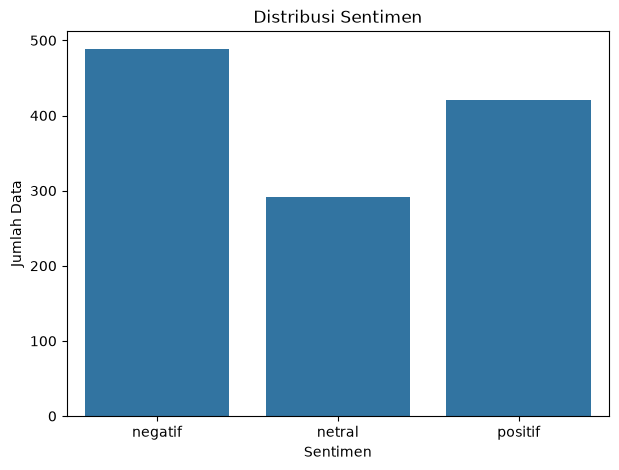

In [10]:

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="sentimen")
plt.title("Distribusi Sentimen")
plt.xlabel("Sentimen")
plt.ylabel("Jumlah Data")
plt.show()


In [11]:

X = df["normalisasi_text"]
y = df["sentimen"]

print("Jumlah data X:", len(X))
print("Jumlah label y:", len(y))
print("Label:", sorted(y.unique()))


Jumlah data X: 1200
Jumlah label y: 1200
Label: ['negatif', 'netral', 'positif']


In [12]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data training :", len(X_train))
print("Data testing  :", len(X_test))


Data training : 960
Data testing  : 240


In [13]:

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=1,
    sublinear_tf=True,
    norm="l2"
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Ukuran matriks training:", X_train_tfidf.shape)
print("Ukuran matriks testing :", X_test_tfidf.shape)


Ukuran matriks training: (960, 1725)
Ukuran matriks testing : (240, 1725)


In [14]:

model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    learning_rate_init=0.001,
    max_iter=500,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.10,
    n_iter_no_change=20
)

print(model)


MLPClassifier(early_stopping=True, hidden_layer_sizes=(64, 32), max_iter=500,
              n_iter_no_change=20, random_state=42)


In [15]:

model.fit(X_train_tfidf, y_train)

print("Training selesai.")
print("Jumlah iterasi:", model.n_iter_)


Training selesai.
Jumlah iterasi: 42


In [16]:

y_pred = model.predict(X_test_tfidf)

print("Contoh hasil prediksi:")
hasil_prediksi = pd.DataFrame({
    "teks": X_test.values,
    "aktual": y_test.values,
    "prediksi": y_pred
})

display(hasil_prediksi.head(20))


Contoh hasil prediksi:


,teks,aktual,prediksi
0,pendaftaran imunisasi anak bisa dilakukan lewa...,netral,netral
1,ada yang tahu jam buka apotek di medan mau cek...,netral,netral
2,anak saya sakit diare tapi apotek denpasar tut...,negatif,negatif
3,antibiotik langka di puskesmas harga naik raky...,negatif,negatif
4,ruang rumah sakit penuh sesak pasien demam tid...,negatif,negatif
5,dinas kesehatan samarinda mengumumkan data kas...,netral,netral
6,stok amoxicillin tersedia lagi di apotek harga...,positif,positif
7,syukur ibu saya sudah pulih dari diare terima ...,positif,positif
8,ada yang tahu jam buka rsud di palembang mau c...,netral,netral
9,klaim skrining tbc ditolak lagi ribet dan meng...,negatif,negatif


In [17]:

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")


Accuracy  : 0.9917
Precision : 0.9919
Recall    : 0.9917
F1-Score  : 0.9917


In [18]:

print(classification_report(
    y_test,
    y_pred,
    digits=4,
    zero_division=0
))


              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        98
      netral     0.9667    1.0000    0.9831        58
     positif     1.0000    0.9762    0.9880        84

    accuracy                         0.9917       240
   macro avg     0.9889    0.9921    0.9903       240
weighted avg     0.9919    0.9917    0.9917       240



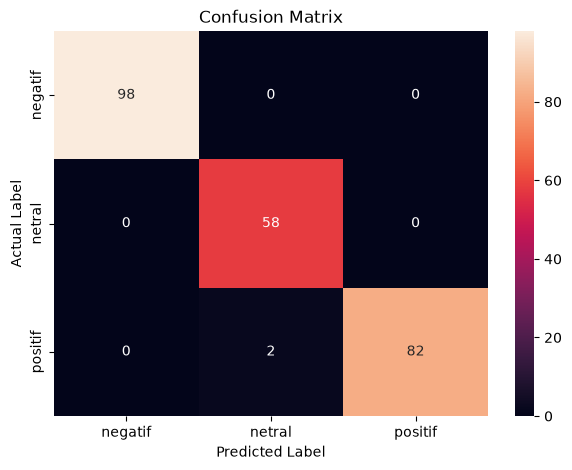

In [19]:

labels = ["negatif", "netral", "positif"]
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


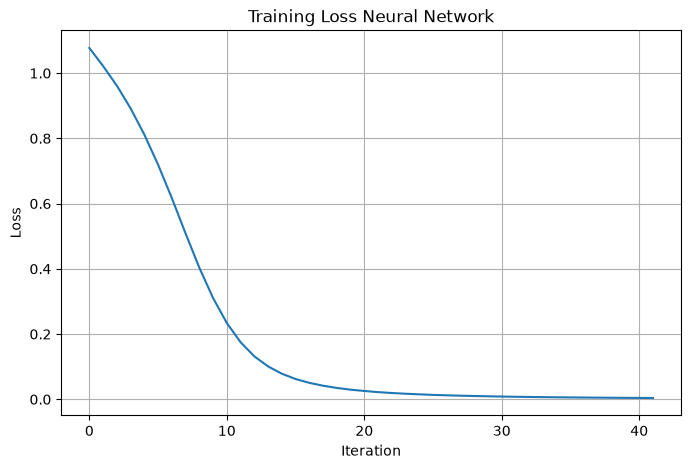

In [20]:

if hasattr(model, "loss_curve_"):
    plt.figure(figsize=(8, 5))
    plt.plot(model.loss_curve_)
    plt.title("Training Loss Neural Network")
    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.grid(True)
    plt.show()
else:
    print("Loss curve tidak tersedia.")


In [21]:

def proses_teks_baru(text):
    clean = cleansing_text(text)
    normal = normalisasi_text(clean)
    return clean, normal


teks_baru = "Pelayanan puskesmas bagus banget, terima kasih sudah membantu"

clean_baru, normal_baru = proses_teks_baru(teks_baru)

vektor_baru = vectorizer.transform([normal_baru])
prediksi_baru = model.predict(vektor_baru)[0]
probabilitas_baru = model.predict_proba(vektor_baru)[0]

print("Teks asli       :", teks_baru)
print("Setelah cleansing:", clean_baru)
print("Setelah normalisasi:", normal_baru)
print("Prediksi sentimen :", prediksi_baru)

print("\nProbabilitas:")
for label, prob in zip(model.classes_, probabilitas_baru):
    print(f"{label:8s}: {prob:.4f}")


Teks asli       : Pelayanan puskesmas bagus banget, terima kasih sudah membantu
Setelah cleansing: pelayanan puskesmas bagus banget terima kasih sudah membantu
Setelah normalisasi: pelayanan puskesmas bagus banget terima kasih sudah membantu
Prediksi sentimen : positif

Probabilitas:
negatif : 0.0131
netral  : 0.0149
positif : 0.9720


In [22]:

joblib.dump(model, "model_sentimen_mlp.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

print("Model berhasil disimpan:")
print("- model_sentimen_mlp.pkl")
print("- tfidf_vectorizer.pkl")


Model berhasil disimpan:
- model_sentimen_mlp.pkl
- tfidf_vectorizer.pkl


In [24]:
# ============================================================
# PREDIKSI BEBERAPA CONTOH TEKS KESEHATAN
# ============================================================

contoh = [
    "Pelayanan puskesmas sangat bagus dan petugasnya ramah",
    "Informasi kesehatan dari pemerintah sangat membantu masyarakat",
    "Pelayanan rumah sakit sangat mengecewakan dan lambat",
]

for t in contoh:
    # Cleansing
    teks_clean = cleansing_text(t)

    # Normalisasi
    teks_normalisasi = normalisasi_text(teks_clean)

    # TF-IDF
    teks_tfidf = vectorizer.transform([teks_normalisasi])

    # Prediksi sentimen
    hasil_prediksi = model.predict(teks_tfidf)[0]

    # Probabilitas setiap kelas
    probabilitas = model.predict_proba(teks_tfidf)[0]

    print("Teks Asli         :", t)
    print("Cleansing         :", teks_clean)
    print("Normalisasi       :", teks_normalisasi)
    print("Prediksi Sentimen :", hasil_prediksi)

    print("Probabilitas:")
    for label, prob in zip(model.classes_, probabilitas):
        print(f"  {label:<8}: {prob:.4f}")

    print("-" * 60)

Teks Asli         : Pelayanan puskesmas sangat bagus dan petugasnya ramah
Cleansing         : pelayanan puskesmas sangat bagus dan petugasnya ramah
Normalisasi       : pelayanan puskesmas sangat bagus dan petugasnya ramah
Prediksi Sentimen : positif
Probabilitas:
  negatif : 0.0614
  netral  : 0.0353
  positif : 0.9033
------------------------------------------------------------
Teks Asli         : Informasi kesehatan dari pemerintah sangat membantu masyarakat
Cleansing         : informasi kesehatan dari pemerintah sangat membantu masyarakat
Normalisasi       : informasi kesehatan dari pemerintah sangat membantu masyarakat
Prediksi Sentimen : positif
Probabilitas:
  negatif : 0.0303
  netral  : 0.1806
  positif : 0.7891
------------------------------------------------------------
Teks Asli         : Pelayanan rumah sakit sangat mengecewakan dan lambat
Cleansing         : pelayanan rumah sakit sangat mengecewakan dan lambat
Normalisasi       : pelayanan rumah sakit sangat mengecewakan d